In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

from astropy import units as u
from astropy.table import Table
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord, Galactocentric
from astropy.constants import G

from gala.units import UnitSystem
import gala.coordinates as gc
usys = UnitSystem(u.kpc, u.Myr, u.Msun, u.radian)

import scipy.interpolate
from scipy.interpolate import InterpolatedUnivariateSpline, UnivariateSpline

import jax
import jax.numpy as jnp
from jax.scipy.stats import gaussian_kde
jax.config.update("jax_enable_x64", True)

from streamsculptor import potential
from streamsculptor import JaxCoords as jc
from streamsculptor import gen_stream_vmapped_with_pert
from streamsculptor.GenerateImpactParams import ImpactGenerator

import diffrax
import interpax
import tqdm


import os

%config InlineBackend.figure_format = 'retina'

# Load data

In [2]:
# read in most likely members
if os.path.exists('../data/gd1_members_0.75.fits'):
    gd1_table = Table.read('../data/gd1_members_0.75.fits')
else:
    ### load in data from Starkman+2024 (you will need to change this directory to your own file location!)
    table = Table.read('../data/gd1_membership_likelhoods.ecsv', format='ascii.ecsv')
    ### Cut at 75% or greater membership probability
    gd1_table = table[table['allstream (MLE)']>=0.75]
    gd1_table.write('../data/gd1_members_0.75.fits', overwrite=True)

ra_rad, dec_rad = jnp.deg2rad(gd1_table['coord'].ra.value), jnp.deg2rad(gd1_table['coord'].dec.value)

In [3]:
@jax.jit
def icrs_to_gd1(ra_rad, dec_rad):
    """
    define a *differentiable* coordinate transfrom from ra and dec --> gd1 phi1, phi2
    Using the rotation matrix from Koposov+2010
    ra_rad: icrs ra [radians]
    dec_red: icrs dec [radians]
    """
    R = jnp.array(
        [
            [-0.4776303088, -0.1738432154, 0.8611897727],
            [0.510844589, -0.8524449229, 0.111245042],
            [0.7147776536, 0.4930681392, 0.4959603976],
        ]
    )


    icrs_vec = jnp.vstack([jnp.cos(ra_rad)*jnp.cos(dec_rad),
                           jnp.sin(ra_rad)*jnp.cos(dec_rad),
                           jnp.sin(dec_rad)]).T

    stream_frame_vec = jnp.einsum('ij,kj->ki',R,icrs_vec)
    
    phi1 = jnp.arctan2(stream_frame_vec[:,1],stream_frame_vec[:,0])*180/jnp.pi
    phi2 = jnp.arcsin(stream_frame_vec[:,2])*180/jnp.pi

    
    return phi1, phi2

phi1, phi2 = icrs_to_gd1(ra_rad, dec_rad)


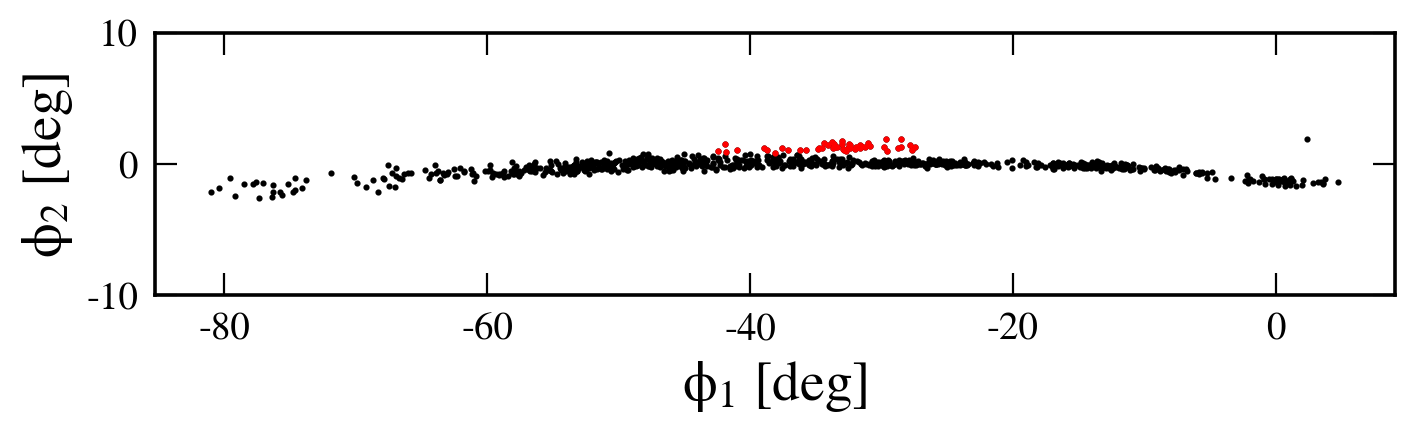

In [4]:
fig, ax = plt.subplots(1,1)
fig.set_size_inches(8,8)
ax.scatter(phi1, phi2,s=1.5,color='k')

## Select some spur stars that we will upweight in the likelihood function
phi2_select_thresh = .85
spur_bool = (phi2 > phi2_select_thresh) & (phi1 < 0.)
ax.scatter(phi1[spur_bool], phi2[spur_bool],s=1.5,color='r')


ax.tick_params(axis='both', which='major', labelsize=14., length=8)
ax.tick_params(axis='both', which='minor', length=3)
ax.set_ylim(-10,10)
ax.set_xlabel(r'$\phi_1$ [deg]',fontsize=20)
ax.set_ylabel(r'$\phi_2$ [deg]',fontsize=20)
ax.set_aspect('equal')

In [5]:
@jax.jit
def get_phi12_from_stream(stream):
    """
    Differentiable helper function that takes us from simulated stream --> phi1, phi2
    """
    ra_s, dec_s, dist_ = jax.vmap(jc.simcart_to_icrs)(stream[:,:3])
    phi1_model, phi2_model = icrs_to_gd1(ra_s*jnp.pi/180, dec_s*jnp.pi/180)
    return phi1_model, phi2_model


In [6]:
def get_icrs_from_stream(stream):
    """
    Helper function that coverts a jax stream object into an astropy ICRS coordinates object
    """
    ra, dec, d = jax.vmap(jc.simcart_to_icrs)(stream[:,:3])
    pmra, pmdec, vr = jax.vmap(jc.simvel_to_ICRS)(stream[:,:3], stream[:,3:])

    ceq = coord.ICRS(ra=ra*u.deg, dec=dec*u.deg, distance=d*u.kpc, pm_ra_cosdec=pmra*u.mas/u.yr, pm_dec=pmdec*u.mas/u.yr, 
                     radial_velocity=(vr*u.kpc/u.Myr).to(u.km/u.s))
    return ceq


# GD-1 in a static Milky Way potential

In [7]:
## Estimated progenitor location today in [kpc, kpc, kpc, kpc/Myr, kpc/Myr, kpc/Myr]
## Estimated in a seperate file, but will provide a good starting point for this notebook
## This file can be found in the data folder of the streamsculptor repository:
## data/GD1_prog/GD1_progenitor.npy
prog_wtoday = jnp.load('../data/GD1_progenitor.npy',allow_pickle=True).item()
pos = prog_wtoday.pos.xyz.to(u.kpc).value
vel = prog_wtoday.vel.d_xyz.to(u.kpc/u.Myr).value
prog_wtoday = jnp.hstack([pos,vel])

print(prog_wtoday)

[-11.88431447   1.61212652   7.14988315  -0.09253346  -0.22701121
  -0.10732978]


In [8]:
## Use Gala's MW potential
pot = potential.GalaMilkyWayPotential(units=usys)

## Define the age of the stream [Myr]
t_age = 2500.0

## Past time at which it dissolved [Myr]
t_dissolve = -300.0

## Get initial conditions
IC = pot.integrate_orbit(w0=prog_wtoday, t0=0.0, t1=-t_age, ts=jnp.array([-t_age])).ys[0]

## Define stripping times. ts[-1] is always the final integration time for gen_stream simulations
ts = jnp.hstack([jnp.linspace(-t_age, t_dissolve, 2_000), jnp.array([0.0])])

## Generate unperturbed stream [l: lead, t: trail]
l, t = pot.gen_stream_vmapped(prog_w0=IC, ts=ts, seed_num=532, Msat=1e4, atol=1e-6, rtol=1e-6, solver=diffrax.Dopri5())
stream = jnp.vstack([l, t])

# get stream coordinates
phi1_model, phi2_model = get_phi12_from_stream(stream[:,:3])

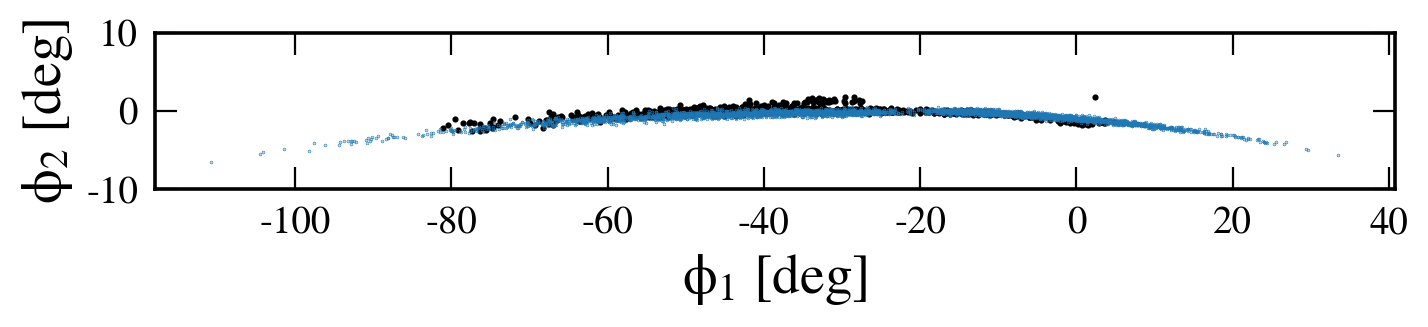

In [9]:
fig, ax = plt.subplots(1,1)
fig.set_size_inches(8,8)
ax.scatter(phi1, phi2,s=1.5,color='k')
ax.scatter(phi1_model, phi2_model,s=.05,color='tab:blue')

    
ax.tick_params(axis='both', which='major', labelsize=14., length=8)
ax.tick_params(axis='both', which='minor', length=3)
ax.set_ylim(-10,10)
ax.set_xlabel(r'$\phi_1$ [deg]',fontsize=20)
ax.set_ylabel(r'$\phi_2$ [deg]',fontsize=20)
ax.set_aspect('equal')

# GD-1 in a Milky Way + LMC potential

In [10]:
from streamsculptor.potential import MW_LMC_Potential, AGAMA_MW_LMC_Potential
# Intialization of this class takes a moment: all of the above splines are being fit (and with jit)
pot_MWLMC = MW_LMC_Potential(units=usys)
# pot_MWLMC_agama = AGAMA_MW_LMC_Potential(units=usys)

In [11]:
# progenitor phase-space location to fit the stream in the MW + LMC potential
prog_wlmc = jnp.array([-11.88431447, 1.61212652, 7.14988315, -0.09, -0.205, -0.1])

In [12]:
## Generate unperturbed stream [l: lead, t: trail]
IC_MWLMC = pot_MWLMC.integrate_orbit(w0=prog_wlmc, t0=0.0, t1=-t_age, ts=jnp.array([-t_age])).ys[0]
l_td, t_td = pot_MWLMC.gen_stream_vmapped(prog_w0=IC_MWLMC, ts=ts, seed_num=532, Msat=1e4, atol=1e-6, rtol=1e-6, solver=diffrax.Dopri5())

stream_td = jnp.vstack([l_td, t_td])
phi1_model_td, phi2_model_td = get_phi12_from_stream(stream_td[:,:3])

# IC = pot.integrate_orbit(w0=prog_wtoday, t0=0.0, t1=-t_age, ts=jnp.array([-t_age])).ys[0]

## Define stripping times. ts[-1] is always the final integration time for gen_stream simulations
# ts = jnp.hstack([jnp.linspace(-t_age, t_dissolve, 2_000), jnp.array([0.0])])

## Generate unperturbed stream [l: lead, t: trail]
# l, t = pot.gen_stream_vmapped(prog_w0=IC, ts=ts, seed_num=532, Msat=1e4, atol=1e-6, rtol=1e-6, solver=diffrax.Dopri5())
# stream = jnp.vstack([l, t])


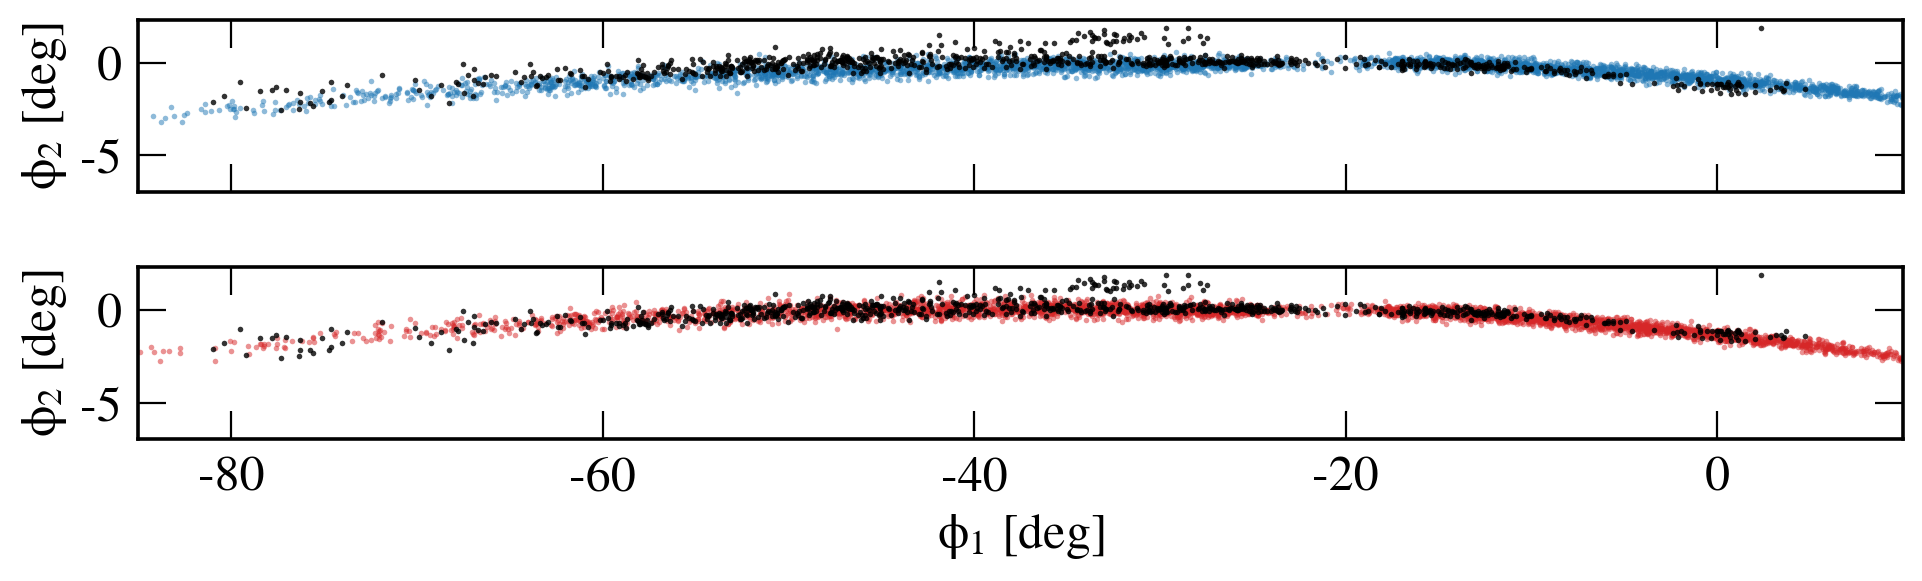

In [13]:
fig, ax = plt.subplots(2,1, figsize=(10,4), sharex=True)

plt.sca(ax[0])
plt.plot(phi1, phi2, 'ko', mew=0, ms=2, alpha=0.8)
plt.plot(phi1_model, phi2_model, 'o', color='tab:blue', mew=0, ms=2, alpha=0.5, zorder=0)

plt.gca().set_aspect('equal')
plt.ylabel('$\phi_2$ [deg]')

plt.sca(ax[1])
plt.plot(phi1, phi2, 'ko', mew=0, ms=2, alpha=0.8)
plt.plot(phi1_model_td, phi2_model_td, 'o', color='tab:red', mew=0, ms=2, alpha=0.5, zorder=0)

plt.xlim(-85, 10)
plt.gca().set_aspect('equal')
plt.xlabel('$\phi_1$ [deg]')
plt.ylabel('$\phi_2$ [deg]')

plt.tight_layout(h_pad=0)

# Simulating impacts

In [14]:
@jax.jit
def gen_perturbed_stream(m, rs):
    pot_SH = potential.SubhaloLinePotential(m=m, 
                                            a=rs,
                                            subhalo_x0=ImpactDict['CartesianImpactParams'][:,:3],
                                            subhalo_v=ImpactDict['CartesianImpactParams'][:,3:],
                                            subhalo_t0=ImpactDict['ImpactFrameParams']['tImpact'],
                                            t_window=jnp.array([150.0]),
                                            units=usys)

    pot_lst = [pot_MWLMC, pot_SH]
    pot_total = potential.Potential_Combine(pot_lst, units=usys)

    IC_ = pot_total.integrate_orbit(w0=prog_wlmc, t0=0.0, t1=-t_age, ts=jnp.array([-t_age]), max_steps=10_000).ys[0]
    l ,t = gen_stream_vmapped_with_pert(pot_base=pot_MWLMC, pot_pert=pot_SH, prog_w0=IC_, ts=ts, seed_num=532, Msat=1e4, max_steps=5_000,
                                        atol=1e-6,rtol=1e-6, solver=diffrax.Dopri5(), dtmin=.05)
    stream = jnp.vstack([l, t])

    return stream

In [126]:
Nimpact = 20

ImpactGen = ImpactGenerator(pot=pot_MWLMC, 
                            tobs=0.0, 
                            stream=stream_td, 
                            stream_phi1=phi1_model_td, 
                            phi1_bounds=[-80.,20.],
                            tImpactBounds=[-2500,0.0],
                            phi1window=.8, 
                            NumImpacts=Nimpact,
                            bImpact_bounds=[0,.1],
                            stripping_times=jnp.hstack([ts[:-1],ts[:-1]]),
                            prog_today=prog_wlmc,
                            seednum=10)#10

ImpactDict = ImpactGen.get_subhalo_ImpactParams()
print(ImpactDict.keys())

dict_keys(['CartesianImpactParams', 'ImpactFrameParams'])


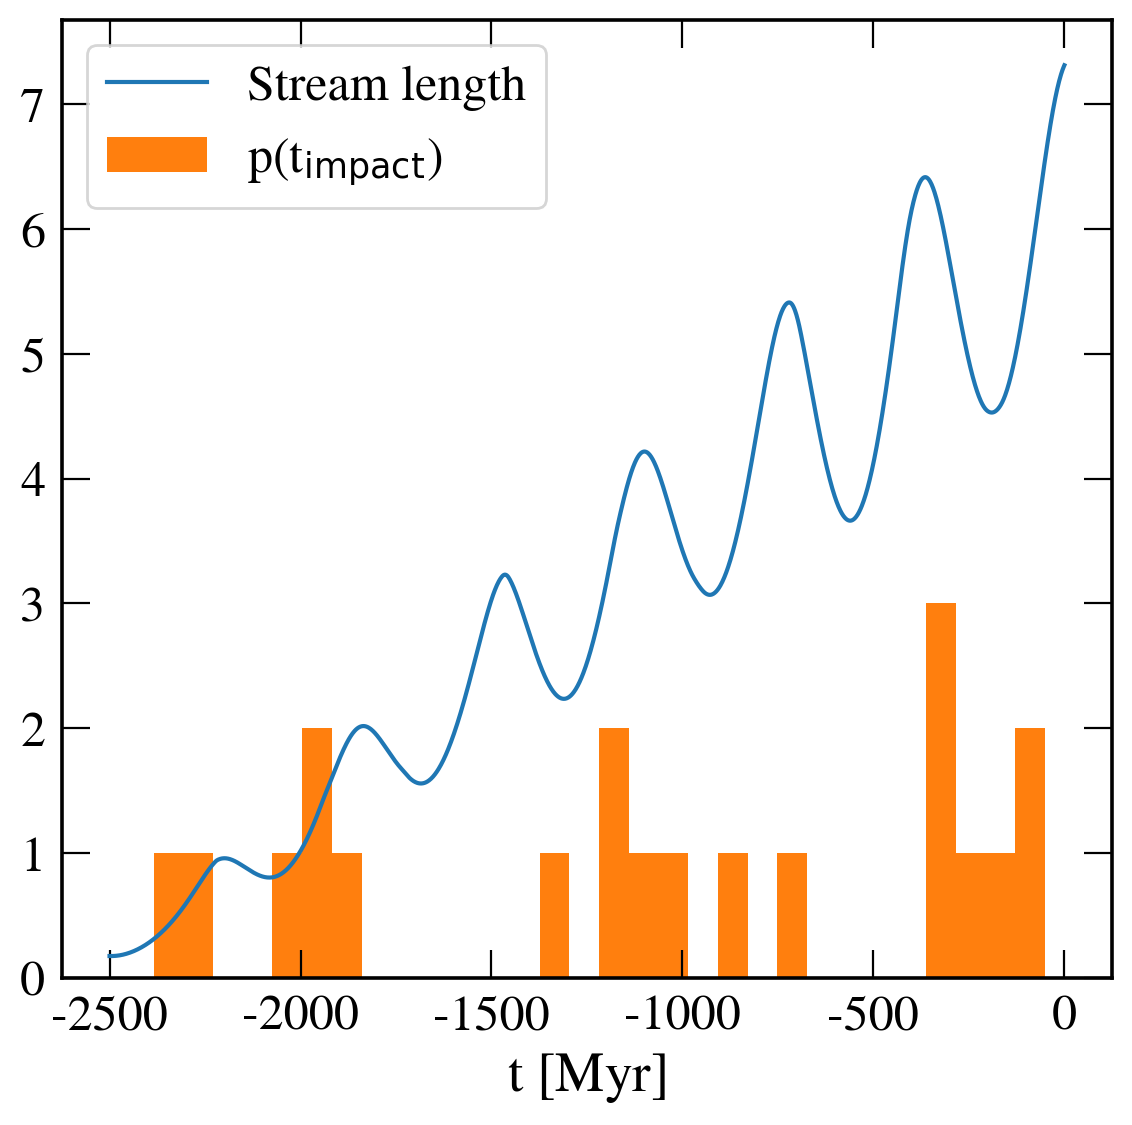

In [127]:
tImp = ImpactDict['ImpactFrameParams']['tImpact']
length_osc = ImpactGen.length_osc

plt.figure(figsize=(6,6))

plt.plot(length_osc['ts'],length_osc['length_func']/3,label='Stream length')
plt.hist(tImp,bins=30, label=r'$p(t_{\rm impact})$');
plt.xlabel(r'$t$ [Myr]',fontsize=20)

plt.legend()
plt.tight_layout()

In [128]:
ImpactDict['ImpactFrameParams'].keys()

dict_keys(['bImpact', 'perp_angle', 'phi1_samples', 'tImpact'])

In [129]:
# Impact parameters (b)
ImpactDict['ImpactFrameParams']['bImpact'], jnp.size(ImpactDict['ImpactFrameParams']['bImpact'])

(Array([0.00485476, 0.05207129, 0.00502186, 0.05399589, 0.03015059,
        0.02254782, 0.09186967, 0.0167615 , 0.09841352, 0.05774199,
        0.07946987, 0.00048576, 0.07767951, 0.00047578, 0.03747469,
        0.06012807, 0.02436086, 0.06561836, 0.00115157, 0.02306978],      dtype=float64),
 20)

In [132]:
## 20 subhalos, masses of 5e6, scale radii of 0.05. This is all tuneable, but will make for 
## a very clearly perturbed stream
m = jnp.ones(Nimpact)*0.5e6 #5e6
rs = jnp.ones(Nimpact)*0.05 #0.05
perturbed_stream = gen_perturbed_stream(m, rs)

In [131]:
perturbed_stream

Array([[inf, inf, inf, inf, inf, inf],
       [inf, inf, inf, inf, inf, inf],
       [inf, inf, inf, inf, inf, inf],
       ...,
       [inf, inf, inf, inf, inf, inf],
       [inf, inf, inf, inf, inf, inf],
       [inf, inf, inf, inf, inf, inf]], dtype=float64)

In [111]:
# get astropy ICRS coordinate objects for stream models
ceq = get_icrs_from_stream(stream_td)
ceq_pert = get_icrs_from_stream(perturbed_stream)

# convert to GD-1 coordinates
cs = ceq.transform_to(gc.GD1Koposov10())
cs_pert = ceq_pert.transform_to(gc.GD1Koposov10())

In [112]:
# fit a spline to radial velocities
order = 3
smoothing = 5000
bbox = [-85, 5]
ind_bbox = (cs.phi1.value>bbox[0]) & (cs.phi1.value<bbox[1])
knots = np.linspace(bbox[0], bbox[1], 2*(order + 1))

ind_sort = np.argsort(cs.phi1.value[ind_bbox])


# phi2_interp = InterpolatedUnivariateSpline(cs.phi1.value[ind_sort], cs.phi2.value[ind_sort], k=order, bbox=bbox)
vr_interp = UnivariateSpline(cs.phi1.value[ind_bbox][ind_sort], cs.radial_velocity.value[ind_bbox][ind_sort], k=order, s=smoothing, bbox=bbox)

vr_bspline = scipy.interpolate.make_interp_spline(cs.phi1.value[ind_bbox][ind_sort], cs.radial_velocity.value[ind_bbox][ind_sort], 
                                                  k=order, bc_type='natural')

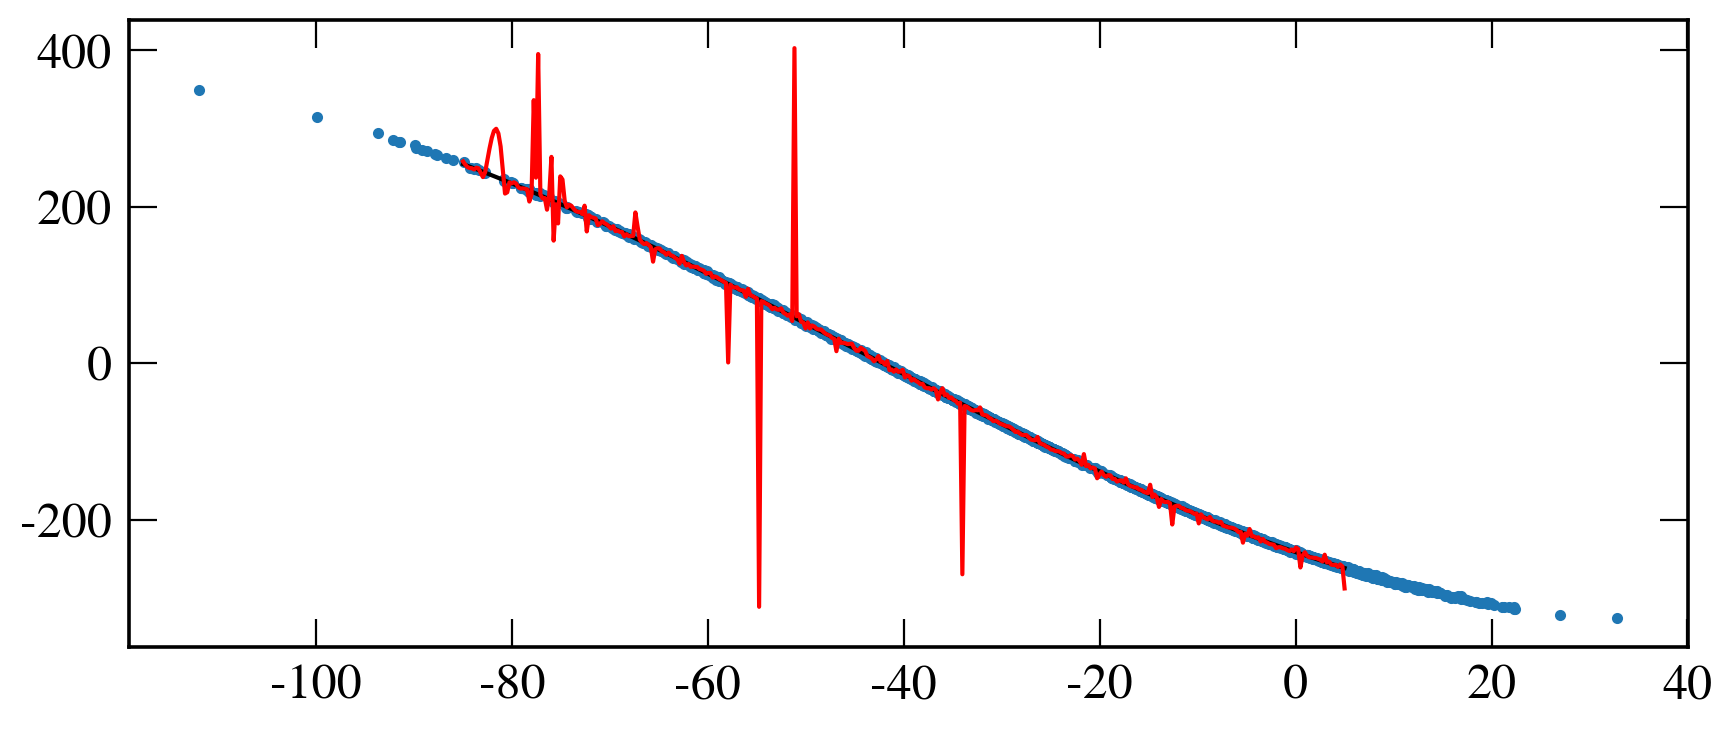

In [113]:
x = np.linspace(bbox[0], bbox[1], 400)

plt.figure(figsize=(9,4))

plt.plot(cs.phi1, cs.radial_velocity, 'o', ms=3)
plt.plot(x, vr_interp(x), 'k-')
plt.plot(x, vr_bspline(x), 'r-')

plt.tight_layout()

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


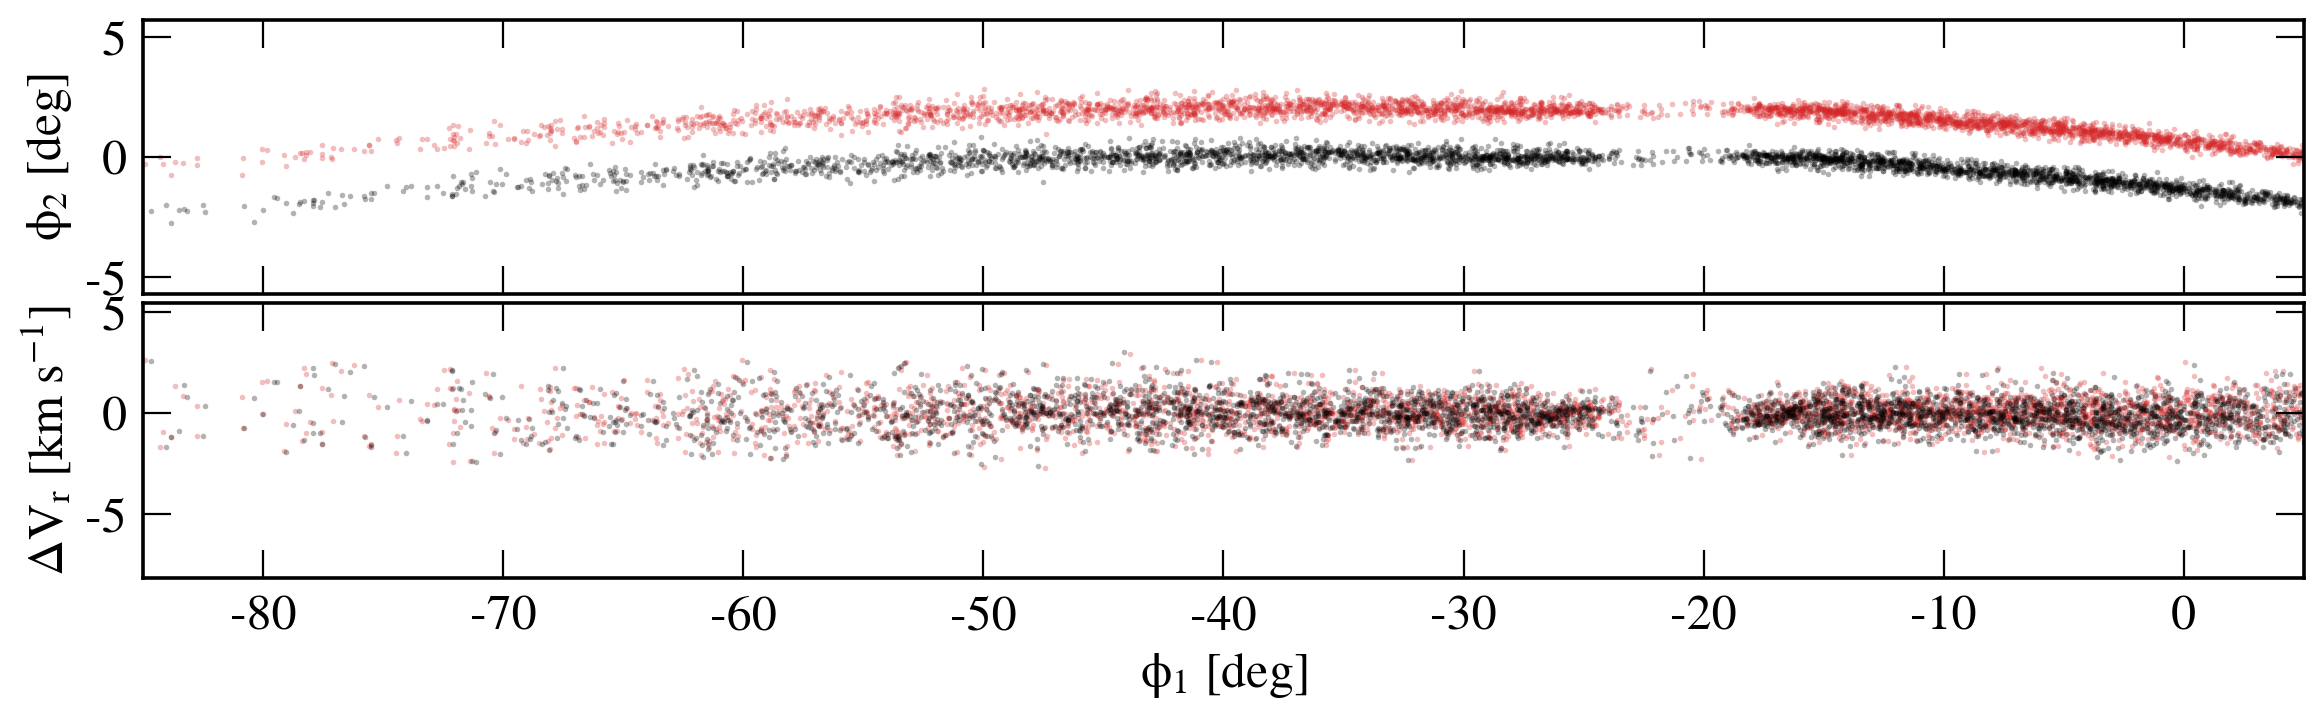

In [114]:
phi1_pert, phi2_pert = get_phi12_from_stream(perturbed_stream[:,:3])

fig, ax = plt.subplots(2, 1, figsize=(12,4), sharex=True)

plt.sca(ax[0])
plt.plot(cs_pert.phi1, cs_pert.phi2, 'ko', mew=0, ms=2, alpha=0.3)
plt.plot(cs.phi1, cs.phi2+2*u.deg, 'o', color='tab:red', mew=0, ms=2, alpha=0.3, zorder=0)

plt.xlim(-85, 5)
plt.ylim(-5,5)
plt.gca().set_aspect('equal', adjustable='datalim')
plt.ylabel('$\phi_2$ [deg]')

plt.sca(ax[1])
# plt.plot(cs_pert.phi1, cs_pert.radial_velocity, 'ko', mew=0, ms=2, alpha=0.3)
plt.plot(cs_pert.phi1, cs_pert.radial_velocity.value - vr_interp(cs_pert.phi1.value), 'ko', mew=0, ms=2, alpha=0.3)
# plt.plot(cs.phi1, cs.radial_velocity.value - vr_interp(cs.phi1.value), 'o', color='tab:red', mew=0, ms=2, alpha=0.3, zorder=0)
plt.plot(cs.phi1, cs.radial_velocity.value - vr_interp(cs.phi1.value), 'o', color='tab:red', mew=0, ms=2, alpha=0.3, zorder=0)

# plt.ylim(-10,10)
plt.xlabel('$\phi_1$ [deg]')
plt.ylabel('$\Delta V_r$ [km s$^{-1}$]')

plt.tight_layout(h_pad=0)

In [115]:
cc = ceq.transform_to(coord.Galactocentric())
cc_pert = ceq_pert.transform_to(coord.Galactocentric())

In [116]:
# kinetic energy
Ek = (np.linalg.norm(cc.velocity.d_xyz, axis=0)**2).to(u.kpc**2*u.Myr**-2)
Ek_pert = (np.linalg.norm(cc_pert.velocity.d_xyz, axis=0)**2).to(u.kpc**2*u.Myr**-2)
dEk = Ek_pert - Ek


# potential energy
xyz = jnp.array(cc.cartesian.xyz.to(u.kpc).value).T
xyz_pert = jnp.array(cc_pert.cartesian.xyz.to(u.kpc).value).T
t = 0

pot_LMC = pot_MWLMC.translating_LMC_pot
pot_MW = pot_MWLMC.pot_MW

Ep = (jax.vmap(pot_LMC.potential, in_axes=(0,None))(xyz, t) + jax.vmap(pot_MW.potential, in_axes=(0,None))(xyz, t))*(u.kpc/u.Myr)**2
Ep_pert = (jax.vmap(pot_LMC.potential, in_axes=(0,None))(xyz_pert, t) + jax.vmap(pot_MW.potential, in_axes=(0,None))(xyz_pert, t))*(u.kpc/u.Myr)**2
dEp = Ep_pert - Ep

# total energy
Etot = Ek + Ep
Etot_pert = Ek_pert + Ep_pert
dE = Etot_pert - Etot

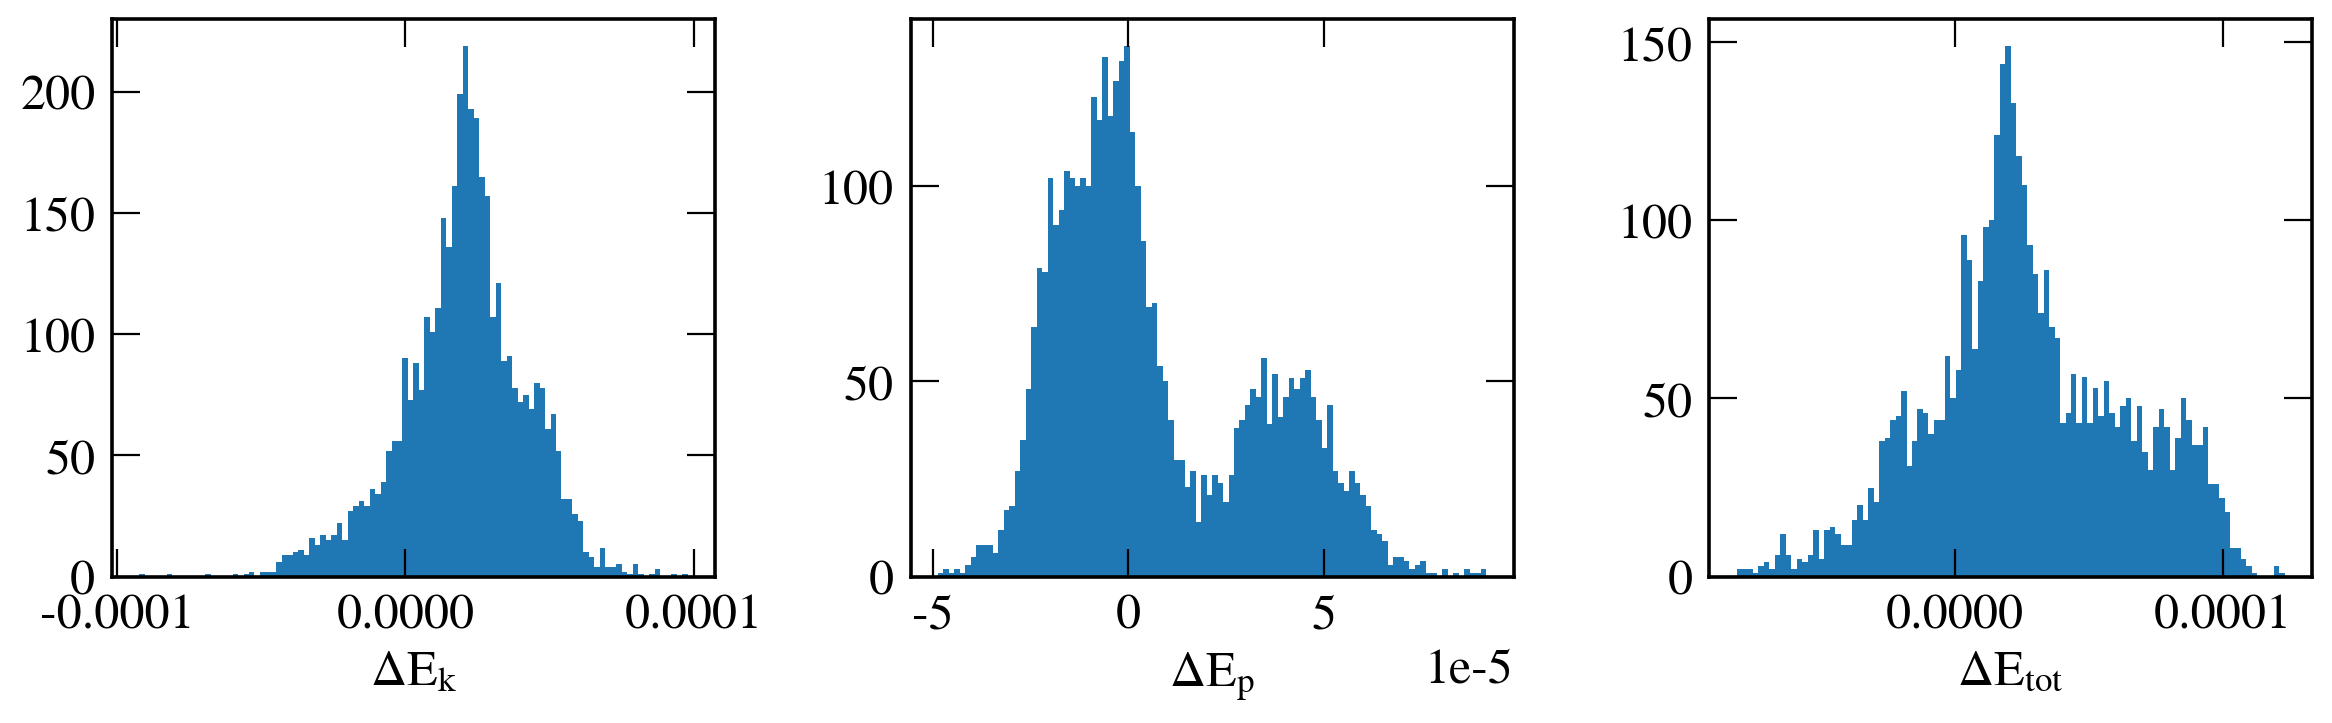

In [117]:
fig, ax = plt.subplots(1,3,figsize=(12,4))
plt.sca(ax[0])
plt.hist(dEk, bins=100)
plt.xlabel('$\Delta E_k$')

plt.sca(ax[1])
plt.hist(dEp, bins=100)
plt.xlabel('$\Delta E_p$')

plt.sca(ax[2])
plt.hist(dE, bins=100)
plt.xlabel('$\Delta E_{tot}$')

plt.tight_layout()

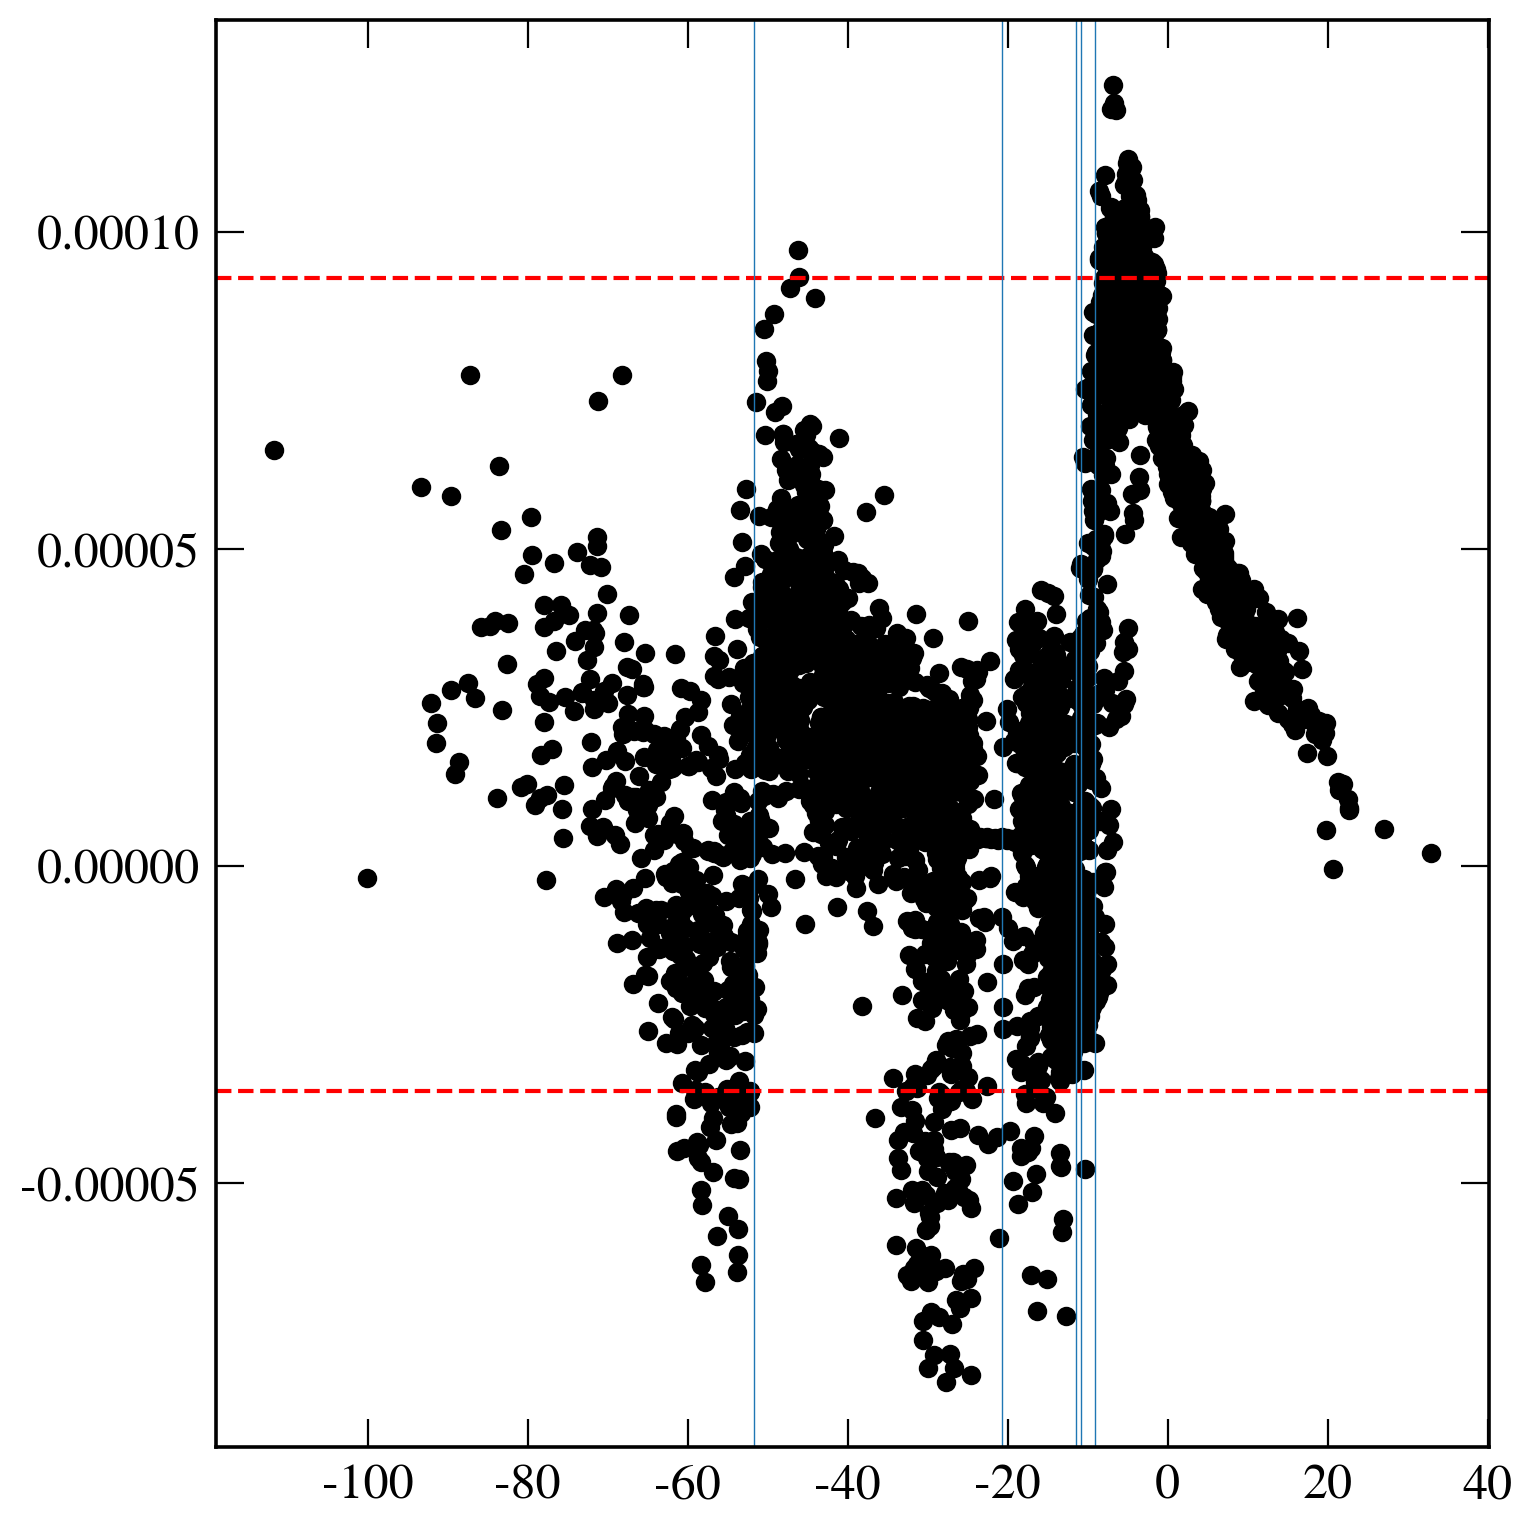

In [118]:
plt.plot(cs_pert.phi1, dE, 'ko')

plt.axhline(np.nanpercentile(dE.value,96), ls='--', color='r')
plt.axhline(np.nanpercentile(dE.value,4), ls='--', color='r')

for p_ in ImpactDict['ImpactFrameParams']['phi1_samples']:
    plt.axvline(p_, lw=0.5)

plt.tight_layout()

In [119]:
ImpactDict['ImpactFrameParams'].keys()

dict_keys(['bImpact', 'perp_angle', 'phi1_samples', 'tImpact'])

In [120]:
ImpactDict['ImpactFrameParams']

{'bImpact': Array([0.00485476, 0.05207129, 0.00502186, 0.05399589, 0.03015059],      dtype=float64),
 'perp_angle': Array([0.8315175 , 1.67167472, 4.72910617, 0.57451152, 0.61483101],      dtype=float64),
 'phi1_samples': Array([-11.50461475, -51.74090365,  -9.13152617, -20.66038545,
        -10.82000453], dtype=float64),
 'tImpact': Array([-2384.64172415,   -51.69173732,  -344.39784085,  -340.10476521,
        -2046.10439256], dtype=float64)}

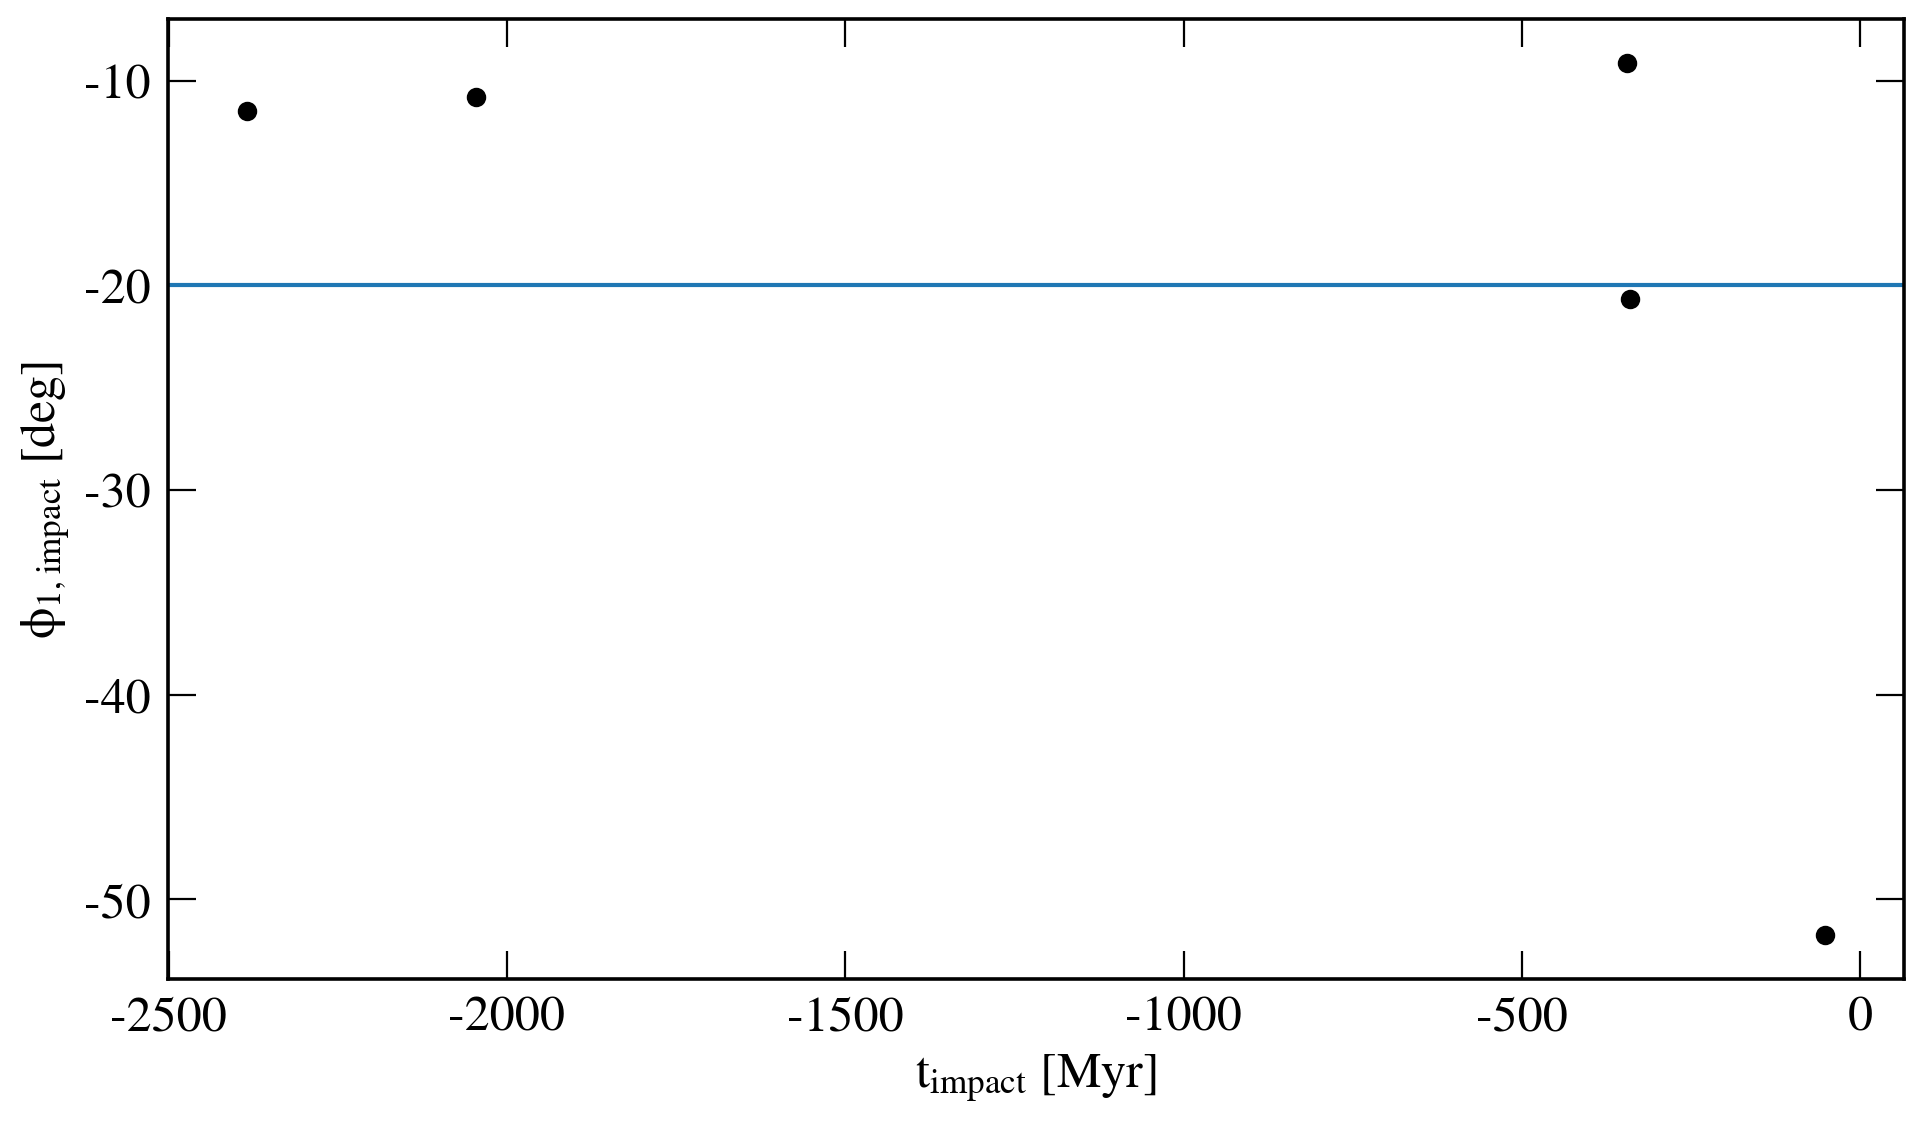

In [125]:
plt.figure(figsize=(10,6))
plt.plot(ImpactDict['ImpactFrameParams']['tImpact'], ImpactDict['ImpactFrameParams']['phi1_samples'], 'ko')
plt.axhline(-20)

plt.xlabel('$t_{impact}$ [Myr]')
plt.ylabel('$\\phi_{1,impact}$ [deg]')

plt.tight_layout()

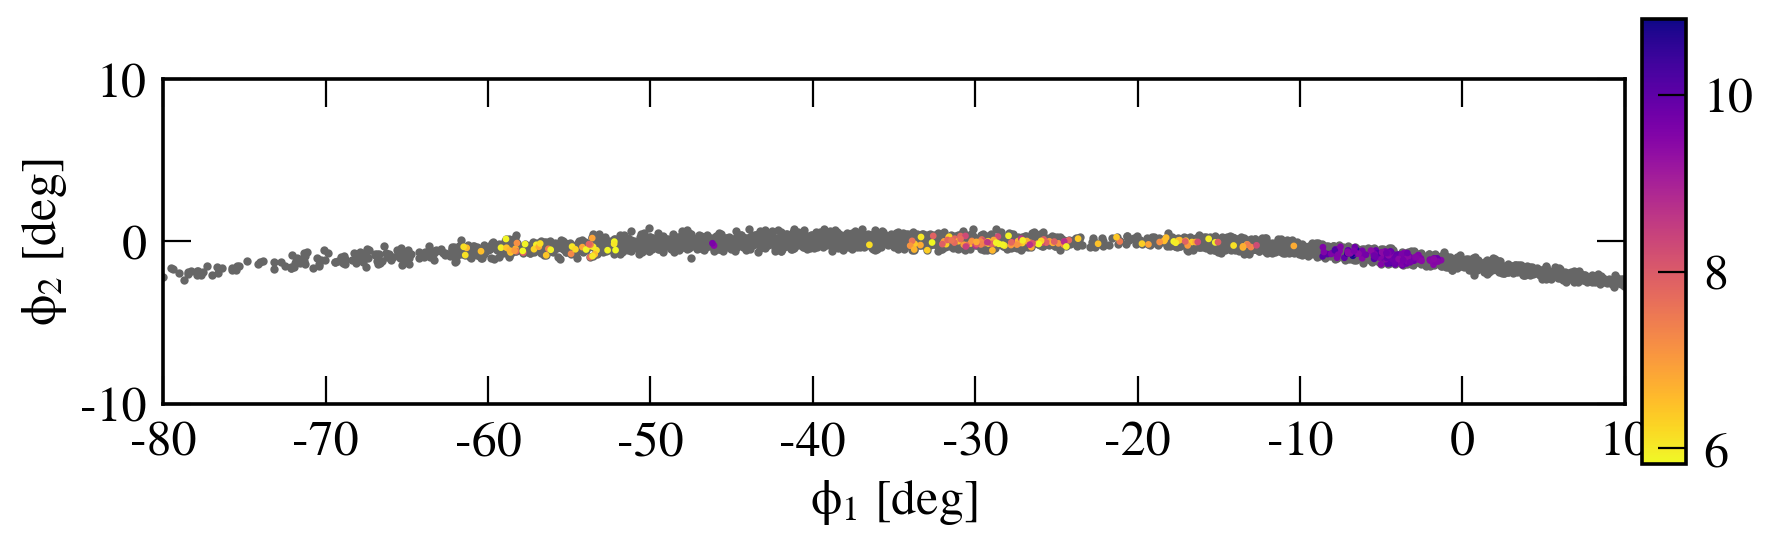

In [121]:
plt.figure(figsize=(10,3))
plt.plot(cs_pert.phi1, cs_pert.phi2, 'o', ms=2, color='0.4', zorder=0)

ind_pert = (dE.value>np.nanpercentile(dE.value,96)) | (dE.value<np.nanpercentile(dE.value,4))
plt.scatter(cs_pert.phi1[ind_pert], cs_pert.phi2[ind_pert], c=np.sqrt(np.abs(dE.to(u.km**2*u.s**-2).value))[ind_pert], 
            s=2, cmap='plasma_r', zorder=1)

plt.xlim(-80,10)
plt.ylim(-10,10)
plt.gca().set_aspect('equal')
plt.xlabel('$\phi_1$ [deg]')
plt.ylabel('$\phi_2$ [deg]')

plt.colorbar(aspect=10, pad=0.01)
plt.tight_layout()

In [122]:
# running median
dphi1 = 0.3
delta_phi1 = 5
phi1_bins = np.arange(-100,20,dphi1)

Nbin = np.size(phi1_bins)
vr_binned = np.empty(Nbin) * u.km/u.s
vr_pert_binned = np.empty(Nbin) * u.km/u.s

for i in range(Nbin):
    ind_phi1 = np.abs(cs.phi1.value - phi1_bins[i])<delta_phi1
    vr_binned[i] = np.median(cs.radial_velocity[ind_phi1])

    ind_phi1 = np.abs(cs_pert.phi1.value - phi1_bins[i])<delta_phi1
    vr_pert_binned[i] = np.median(cs_pert.radial_velocity[ind_phi1])

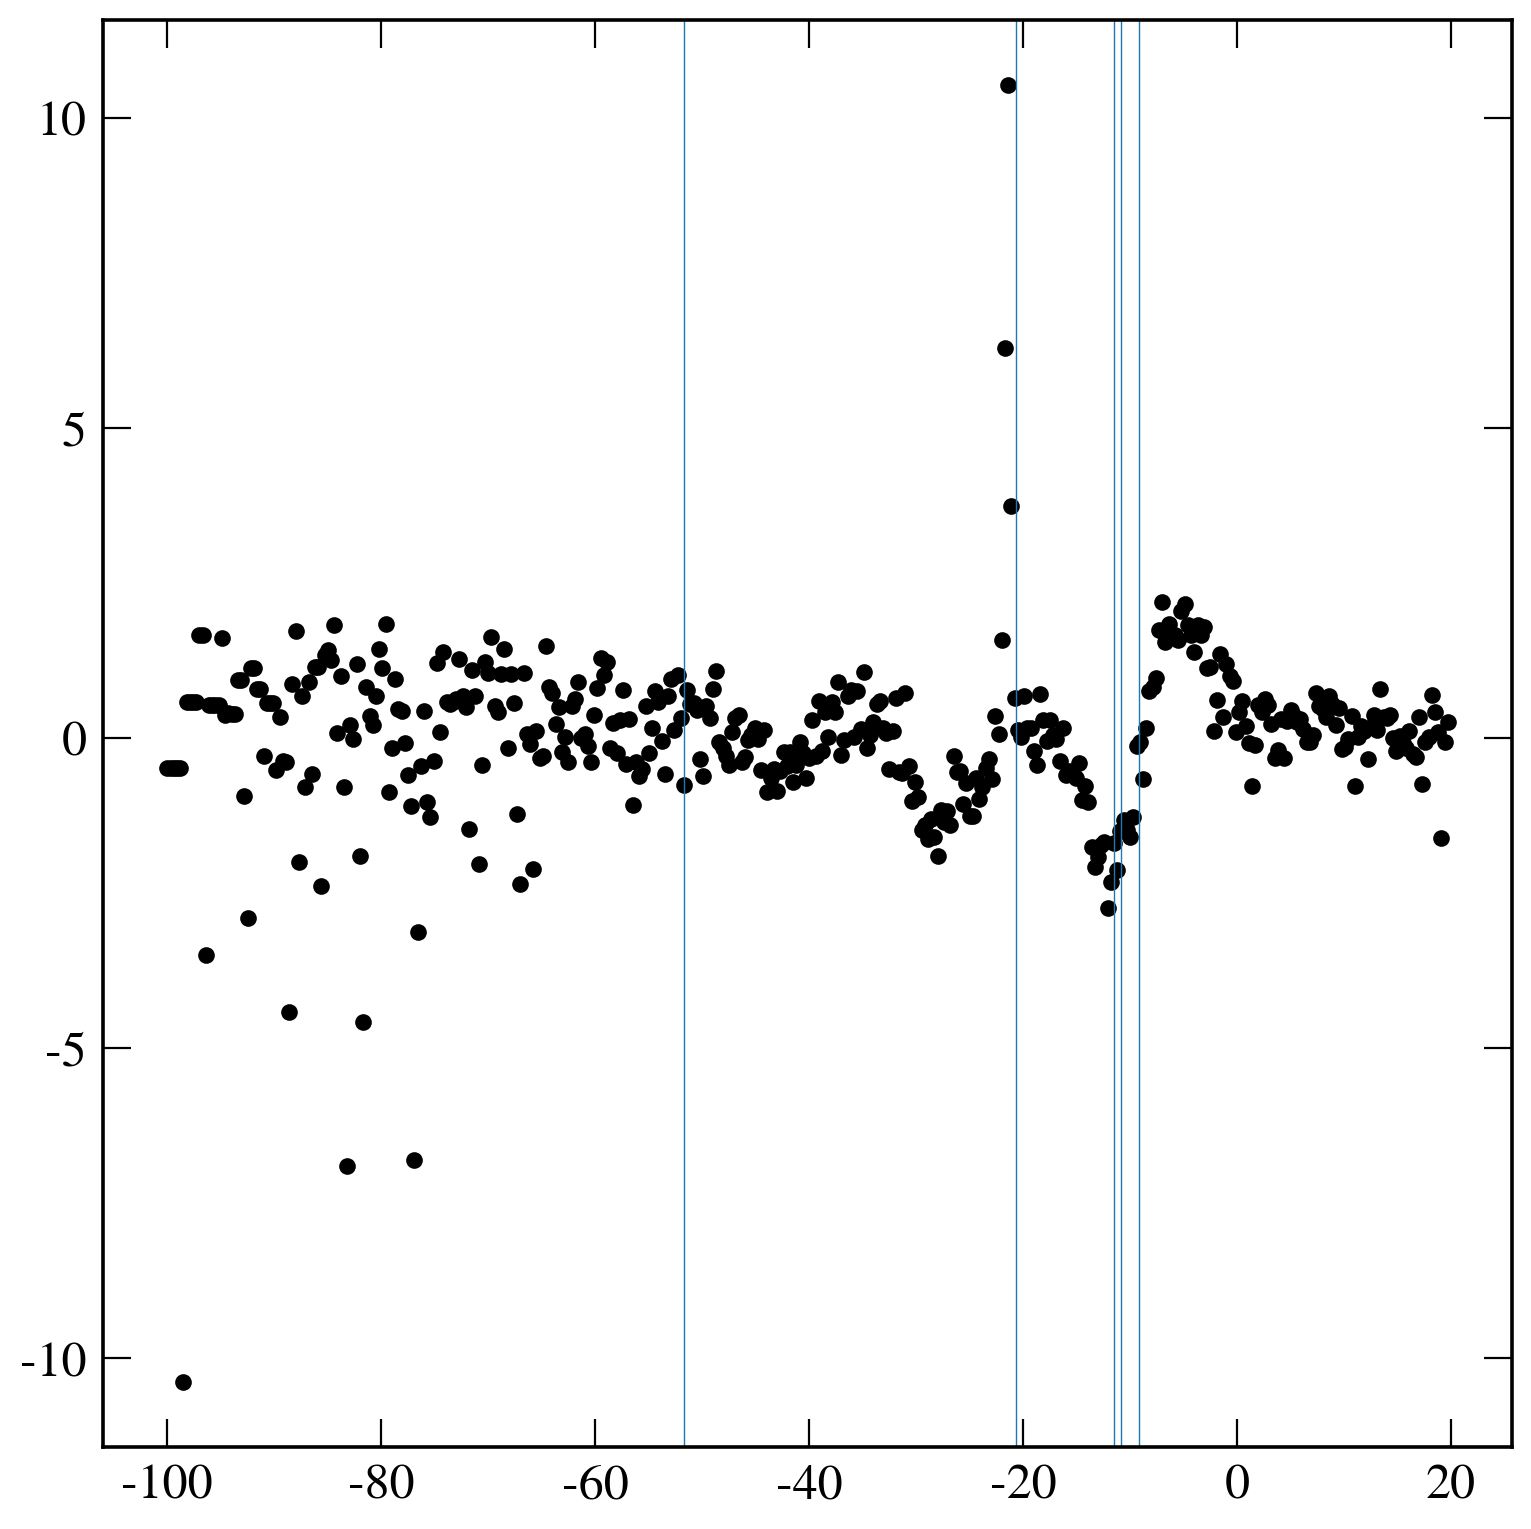

In [123]:
plt.plot(phi1_bins, vr_binned - vr_pert_binned, 'ko', mew=0, ms=6, alpha=1)

for p_ in ImpactDict['ImpactFrameParams']['phi1_samples']:
    plt.axvline(p_, lw=0.5)

# vlim = 1.5
# plt.axhline(vlim)
# plt.axhline(-vlim)

plt.tight_layout()

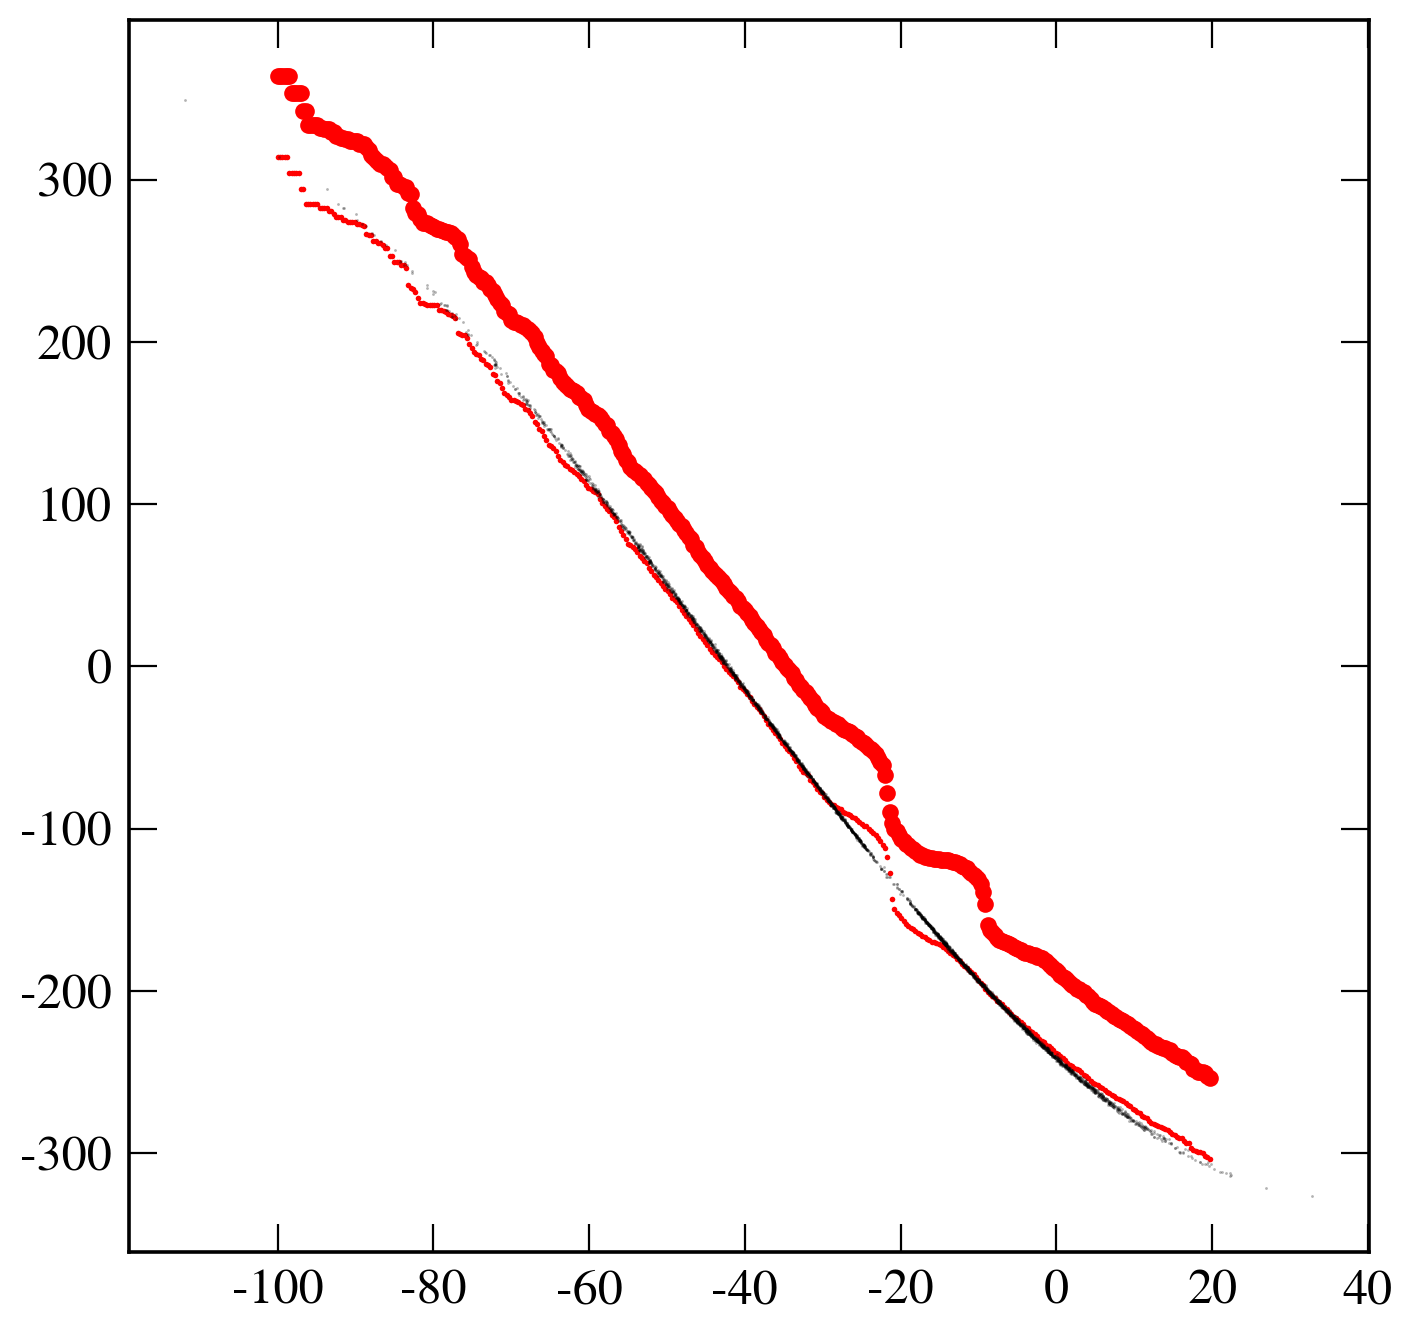

In [33]:
plt.plot(phi1_bins, vr_binned, 'ro', mew=0, ms=2, alpha=1)
plt.plot(cs.phi1, cs.radial_velocity, 'ko', mew=0, ms=1, alpha=0.3)
plt.plot(phi1_bins, vr_pert_binned.value + 50, 'ro', mew=0, ms=6, alpha=1)
